# Fase C: Modelos de Machine Learning

## Diseño

Se hace una comparacion con K-Nearest Neighbors (KNN), Arbol de Decision y Random Forest. Se informa Accuracy, Precision, Recall, F1 de clase positiva y matrices de confusion. **Dado que el contexto de negocio son siniestros viales, se prioriza no dejar escapar siniestros con victimas** (minimizar falsos negativos). El modelo final se selecciona por Recall y F1 de la clase 1 y por AUC, considerando tambien su interpretabilidad. La precision se controla ajustando el umbral de decision.

Se realiza `train_test_split` estratificado 80/20. El escalado de KNN se ajusta dentro de un Pipeline y solamente con entrenamiento para evitar data leakage. K-Means segmenta predictores sin emplear la etiqueta; Silhouette y Davies-Bouldin se calculan en una muestra de prueba.

**Limitacion heredada:** el parquet ya contiene imputaciones y One-Hot hechos en B antes de dividir los datos. En C no se puede deshacer ese procesamiento desde el parquet; el escalado y los modelos si se ajustan despues del split. Para prevenir tambien cualquier fuga por imputacion, B tendria que exportar datos antes de imputar y C ajustar el imputador dentro del pipeline.

In [9]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import time
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, davies_bouldin_score, f1_score, precision_score, recall_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TARGET = "con_victimas"
CANDIDATES = [Path("datos_limpios.parquet"), Path("entrega/datos_limpios.parquet"), Path("p2p3/entrega/datos_limpios.parquet"), Path("../entrega/datos_limpios.parquet")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("No se encontro datos_limpios.parquet. Rutas probadas: " + ", ".join(str(p.resolve()) for p in CANDIDATES))
data = pd.read_parquet(DATA_PATH)
required = {TARGET, "id_siniestro", "fecha"}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Faltan columnas requeridas: {sorted(missing)}")
if data[TARGET].isna().any() or set(data[TARGET].unique()) != {0, 1}:
    raise ValueError("El objetivo debe estar completo y contener clases 0 y 1.")
if not data["id_siniestro"].is_unique:
    raise ValueError("id_siniestro contiene duplicados.")
print(f"Parquet: {DATA_PATH.resolve()} | filas: {len(data):,} | columnas: {data.shape[1]}")
display(data[TARGET].value_counts(normalize=True).sort_index().rename("proporcion").to_frame())

Parquet: C:\Users\megap\Desktop\Datos\Ciencias-de-datos\p2p3\entrega\datos_limpios.parquet | filas: 370,998 | columnas: 38


,proporcion
con_victimas,
0,0.862905
1,0.137095


## 1. Preparacion y split

Se eliminan del conjunto de predictores el objetivo, el identificador y la fecha original. Las variables temporales derivadas en B se conservan. Se comprueba la ausencia de nulos, infinitos y columnas no numericas. No se escala antes de la separacion.

In [10]:
X = data.drop(columns=[TARGET, "id_siniestro", "fecha"])
y = data[TARGET].astype("int8")
non_numeric = X.select_dtypes(exclude=[np.number, "bool"]).columns.tolist()
if non_numeric:
    raise TypeError(f"Hay predictores no numericos: {non_numeric}")
if X.isna().any().any():
    raise ValueError(f"Quedan nulos en predictores: {X.columns[X.isna().any()].tolist()}")
if not np.isfinite(X.to_numpy(dtype="float64")).all():
    raise ValueError("Hay valores infinitos en los predictores.")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
print(f"Entrenamiento: {len(X_train):,} | prueba: {len(X_test):,} | predictores: {X.shape[1]}")
display(pd.DataFrame({"entrenamiento": y_train.value_counts(normalize=True).sort_index(), "prueba": y_test.value_counts(normalize=True).sort_index()}))

Entrenamiento: 296,798 | prueba: 74,200 | predictores: 35


,entrenamiento,prueba
con_victimas,,
0,0.862903,0.862911
1,0.137097,0.137089


## 2. Entrenamiento y evaluacion supervisada

Se comparan tres modelos: KNN (sensible a la escala, se usa Pipeline), Arbol de Decision (interpretable) y Random Forest (potente). `class_weight` contrarresta el desbalance. Todos los modelos se ajustan solo con entrenamiento y se comparan solo en el conjunto de prueba.

**Criterio de seleccion:** Dado que el negocio prioriza detectar los siniestros con victimas (evitar falsos negativos), el modelo final se elige por Recall y F1 en la clase 1, junto con el AUC de la seccion 4.1. Se registra el tiempo de entrenamiento como referencia.

Entrenado: KNN (con escalado) (0.38 segundos)


Entrenado: Arbol de Decision (2.20 segundos)
Entrenado: Random Forest (28.07 segundos)


,Modelo,Accuracy,Precision clase 1,Recall clase 1,F1 clase 1,Tiempo Entrenamiento (s)
0,Random Forest,0.8369,0.4472,0.8043,0.5748,28.07
1,Arbol de Decision,0.8366,0.4465,0.8003,0.5732,2.20
2,KNN (con escalado),0.8873,0.6300,0.4309,0.5118,0.38


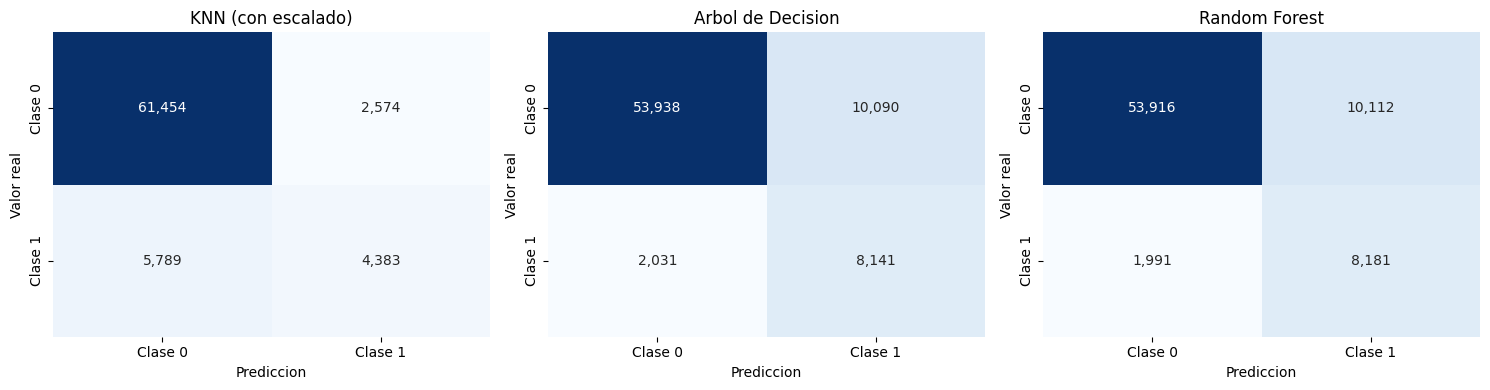


Modelo final: Random Forest


In [11]:
# Definicion de modelos (KNN reemplaza a Regresion Logistica para demostrar escalado)
models = {
    "KNN (con escalado)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1))
    ]),
    "Arbol de Decision": DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=160, max_depth=18, min_samples_leaf=10, max_features="sqrt", 
        class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE
    ),
}

predictions = {}
confusion_matrices = {}
rows = []

for name, model in models.items():
    # Medir tiempo de entrenamiento
    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start_time
    print(f"Entrenado: {name} ({train_time:.2f} segundos)")
    
    # Predecir y evaluar
    pred = model.predict(X_test)
    predictions[name] = pred
    confusion_matrices[name] = confusion_matrix(y_test, pred, labels=[0, 1])
    
    rows.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision clase 1": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "Recall clase 1": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "F1 clase 1": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "Tiempo Entrenamiento (s)": train_time
    })

# Crear tabla comparativa, ordenada por F1 y Recall de la clase 1 (criterio de negocio)
results = pd.DataFrame(rows).sort_values(["F1 clase 1", "Recall clase 1"], ascending=False).reset_index(drop=True)
display(results.style.format({
    "Accuracy": "{:.4f}",
    "Precision clase 1": "{:.4f}",
    "Recall clase 1": "{:.4f}",
    "F1 clase 1": "{:.4f}",
    "Tiempo Entrenamiento (s)": "{:.2f}"
}))

# Graficar matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, matrix) in zip(axes, confusion_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, 
                xticklabels=["Clase 0", "Clase 1"], yticklabels=["Clase 0", "Clase 1"], ax=ax)
    ax.set(title=name, xlabel="Prediccion", ylabel="Valor real")
plt.tight_layout()
plt.show()

# Modelo final elegido por recall, F1 y AUC (justificacion y verificacion en la seccion 5)
selected_model = "Random Forest"
print(f"\nModelo final: {selected_model}")

## 3. Segmentacion con K-Means

La segmentacion usa variables de tiempo, tipo de vehiculo y caracteristicas del evento, sin incluir `con_victimas`. StandardScaler y K-Means se ajustan unicamente con entrenamiento. Para evaluar sobre prueba, se obtiene una muestra reproducible de hasta 5.000 filas. Silhouette mas alto y Davies-Bouldin mas bajo indican mejor separacion.

In [12]:
cluster_columns = ["anio", "mes", "es_fin_de_semana", "es_interseccion", "numero_vehiculos_transf", "categoria_siniestro_ord", "involucra_motocicleta", "involucra_liviano", "involucra_pesado", "involucra_no_motorizado"]
cluster_columns += sorted(c for c in X.columns if c.startswith("dia_semana_"))
missing_cluster = set(cluster_columns) - set(X.columns)
if missing_cluster:
    raise ValueError(f"Faltan variables para clustering: {sorted(missing_cluster)}")
X_train_cluster = X_train[cluster_columns].astype("float64")
X_test_cluster = X_test[cluster_columns].astype("float64")
cluster_scaler = StandardScaler()
X_train_scaled = cluster_scaler.fit_transform(X_train_cluster)
X_test_scaled = cluster_scaler.transform(X_test_cluster)
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_train_scaled)
clusters_test = kmeans.predict(X_test_scaled)
rng = np.random.default_rng(RANDOM_STATE)
sample_size = min(5000, len(X_test_scaled))
sample_idx = rng.choice(len(X_test_scaled), size=sample_size, replace=False)
X_sample, labels_sample = X_test_scaled[sample_idx], clusters_test[sample_idx]
if np.unique(labels_sample).size < 2:
    raise ValueError("La muestra de prueba contiene menos de dos clusters.")
cluster_scores = pd.DataFrame({"Metrica": ["Silhouette Score", "Davies-Bouldin"], "Valor": [silhouette_score(X_sample, labels_sample), davies_bouldin_score(X_sample, labels_sample)]})
print(f"K-Means k=4; entrenado con {len(X_train_cluster):,}; metricas sobre {sample_size:,} filas de prueba")
display(cluster_scores.style.format({"Valor": "{:.4f}"}))
profile = X_test_cluster.copy()
profile["cluster"] = clusters_test
display(profile.groupby("cluster").agg(registros=("anio", "size"), anio_promedio=("anio", "mean"), vehiculos_promedio=("numero_vehiculos_transf", "mean"), fin_de_semana=("es_fin_de_semana", "mean"), interseccion=("es_interseccion", "mean"), motocicleta=("involucra_motocicleta", "mean"), liviano=("involucra_liviano", "mean"), pesado=("involucra_pesado", "mean")).round(3))

K-Means k=4; entrenado con 296,798; metricas sobre 5,000 filas de prueba


,Metrica,Valor
0,Silhouette Score,0.1812
1,Davies-Bouldin,1.7531


,registros,anio_promedio,vehiculos_promedio,fin_de_semana,interseccion,motocicleta,liviano,pesado
cluster,,,,,,,,
0,42265,2018.867,1.107,0.000,0.460,0.174,0.324,0.090
1,10531,2018.866,1.106,0.000,0.455,0.172,0.327,0.091
2,3819,2018.918,0.693,0.292,0.406,0.388,0.249,0.115
3,17585,2018.832,1.107,1.000,0.447,0.173,0.300,0.070


## 4. Visualizaciones finales de los modelos

Estas gráficas resumen los resultados para el informe y la presentación (Fase D). Todas usan los modelos ya entrenados arriba y se evalúan **solo con el conjunto de prueba**. Se guardan en la carpeta `graficas/` con el prefijo `fc_`.

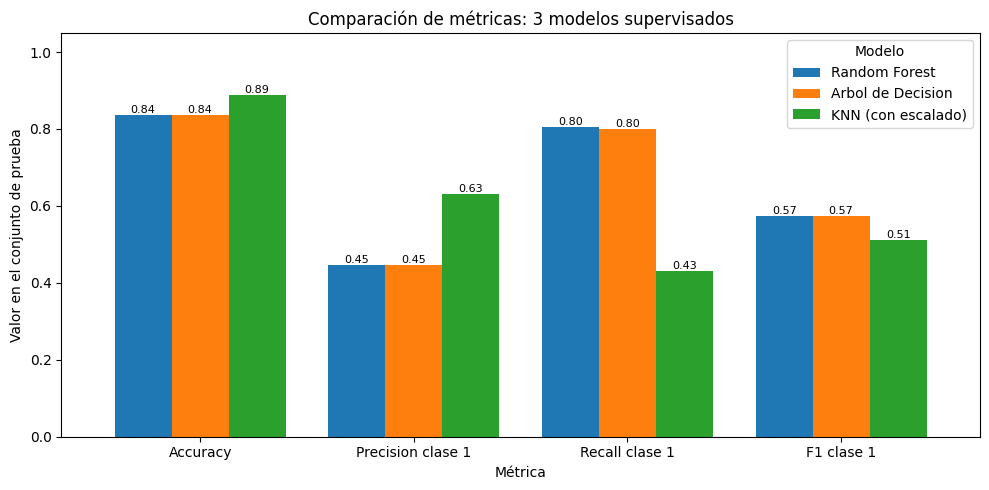

In [13]:
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve

RUTA_GRAFICAS = DATA_PATH.parent / "graficas"
RUTA_GRAFICAS.mkdir(exist_ok=True)

# Comparación de métricas de los 3 modelos (misma tabla de la sección 2, en barras)
metricas = ["Accuracy", "Precision clase 1", "Recall clase 1", "F1 clase 1"]
tabla_metricas = results.set_index("Modelo")[metricas]

ax = tabla_metricas.T.plot(kind="bar", figsize=(10, 5), rot=0, width=0.8)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.2f", fontsize=8)
ax.set_title("Comparación de métricas: 3 modelos supervisados")
ax.set_xlabel("Métrica")
ax.set_ylabel("Valor en el conjunto de prueba")
ax.set_ylim(0, 1.05)
ax.legend(title="Modelo")
plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fc_01_comparacion_metricas.png")
plt.show()

### 4.1 Curvas ROC

La curva ROC muestra, para cada umbral de decisión, cuántos siniestros con víctimas detecta el modelo (eje Y) frente a cuántas falsas alarmas genera (eje X). El AUC resume la curva en un número: 0,5 es azar y 1 es perfecto. A diferencia de la precisión y el recall, no depende del umbral de 0,5.

KNN compara cada fila de prueba con todo el conjunto de entrenamiento, así que calcular sus probabilidades es lento. Por eso su curva se calcula sobre una muestra aleatoria de 12.000 filas de prueba; la de los árboles usa el conjunto de prueba completo.

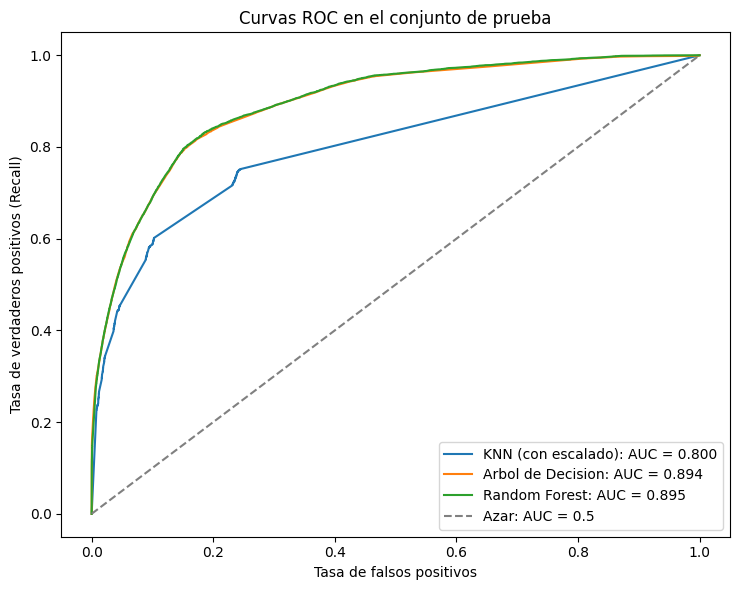

,Modelo,AUC,Filas evaluadas
0,KNN (con escalado),0.8002,"12,000"
1,Arbol de Decision,0.8940,"74,200"
2,Random Forest,0.8954,"74,200"


In [14]:
rng_roc = np.random.default_rng(RANDOM_STATE)
idx_knn = rng_roc.choice(len(X_test), size=min(12000, len(X_test)), replace=False)

fig, ax = plt.subplots(figsize=(7.5, 6))
filas_auc = []
for name, model in models.items():
    # KNN se evalúa sobre la muestra; los árboles, sobre todo el conjunto de prueba
    if name.startswith("KNN"):
        X_eval, y_eval = X_test.iloc[idx_knn], y_test.iloc[idx_knn]
    else:
        X_eval, y_eval = X_test, y_test
    proba = model.predict_proba(X_eval)[:, 1]
    fpr, tpr, _ = roc_curve(y_eval, proba)
    auc = roc_auc_score(y_eval, proba)
    filas_auc.append({"Modelo": name, "AUC": auc, "Filas evaluadas": len(y_eval)})
    ax.plot(fpr, tpr, label=f"{name}: AUC = {auc:.3f}")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar: AUC = 0.5")
ax.set_title("Curvas ROC en el conjunto de prueba")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fc_02_curvas_roc.png")
plt.show()

display(pd.DataFrame(filas_auc).style.format({"AUC": "{:.4f}", "Filas evaluadas": "{:,}"}))

### 4.2 Importancia de variables (Random Forest)

La importancia por impureza mide cuánto ayuda cada variable a separar los siniestros con y sin víctimas dentro de los árboles del bosque. Las importancias de todas las variables suman 1. Indica qué usa el modelo para decidir, no si la relación es causal.

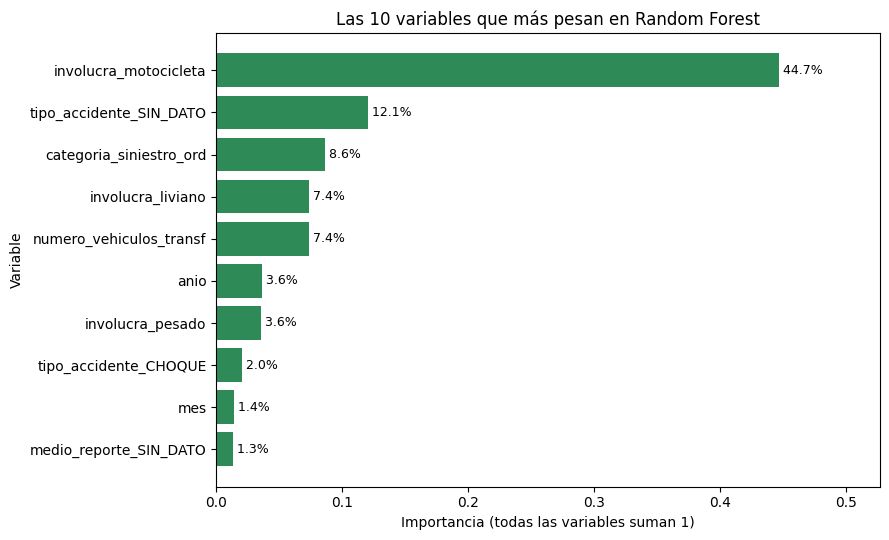

,importancia
involucra_motocicleta,0.4467
tipo_accidente_SIN_DATO,0.1208
categoria_siniestro_ord,0.0862
involucra_liviano,0.0739
numero_vehiculos_transf,0.0736
anio,0.0364
involucra_pesado,0.0358
tipo_accidente_CHOQUE,0.0204
mes,0.0144
medio_reporte_SIN_DATO,0.0134


In [15]:
bosque = models["Random Forest"]
importancias = (
    pd.Series(bosque.feature_importances_, index=X_train.columns)
    .sort_values(ascending=False)
)
top_importancias = importancias.head(10).sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top_importancias.index, top_importancias.values, color="seagreen")
for posicion, valor in enumerate(top_importancias.values):
    ax.text(valor, posicion, f" {valor:.1%}", va="center", fontsize=9)
ax.set_title("Las 10 variables que más pesan en Random Forest")
ax.set_xlabel("Importancia (todas las variables suman 1)")
ax.set_ylabel("Variable")
ax.set_xlim(0, top_importancias.max() * 1.18)
plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fc_03_importancia_variables.png")
plt.show()

display(importancias.head(10).round(4).to_frame("importancia"))

### 4.3 Clusters de K-Means

**Izquierda:** los clusters proyectados en 2 dimensiones con PCA. El PCA se usa solo para dibujar: se ajusta con el entrenamiento escalado y proyecta la misma muestra de 5.000 filas de prueba con la que se calcularon Silhouette y Davies-Bouldin.

**Derecha:** el porcentaje de siniestros con víctimas en cada cluster. La etiqueta `con_victimas` no se usó para formar los grupos; se cruza después para ver si algún segmento concentra más riesgo.

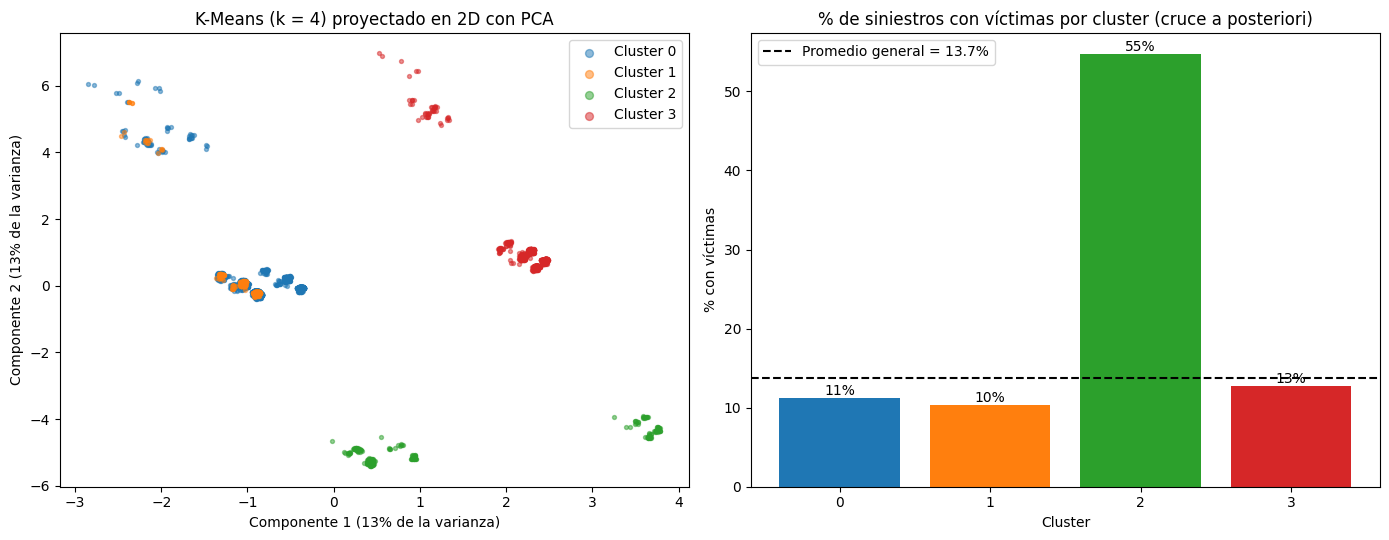

,registros,% con víctimas
0,42265,11.2
1,10531,10.3
2,3819,54.7
3,17585,12.8


In [16]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_scaled)
coordenadas = pca.transform(X_sample)
varianza = pca.explained_variance_ratio_

# Tasa de víctimas por cluster en todo el conjunto de prueba (cruce a posteriori)
y_test_array = y_test.to_numpy()
tasa_cluster = pd.Series(y_test_array).groupby(clusters_test).mean() * 100
promedio_victimas = y_test_array.mean() * 100
colores = sns.color_palette("tab10", kmeans.n_clusters)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for k in range(kmeans.n_clusters):
    en_cluster = labels_sample == k
    axes[0].scatter(coordenadas[en_cluster, 0], coordenadas[en_cluster, 1],
                    s=8, alpha=0.5, color=colores[k], label=f"Cluster {k}")
axes[0].set_title(f"K-Means (k = {kmeans.n_clusters}) proyectado en 2D con PCA")
axes[0].set_xlabel(f"Componente 1 ({varianza[0]:.0%} de la varianza)")
axes[0].set_ylabel(f"Componente 2 ({varianza[1]:.0%} de la varianza)")
axes[0].legend(markerscale=2)

axes[1].bar(tasa_cluster.index.astype(str), tasa_cluster.values,
            color=[colores[k] for k in tasa_cluster.index])
for posicion, valor in enumerate(tasa_cluster.values):
    axes[1].text(posicion, valor, f"{valor:.0f}%", ha="center", va="bottom")
axes[1].axhline(promedio_victimas, color="black", linestyle="--",
                label=f"Promedio general = {promedio_victimas:.1f}%")
axes[1].set_title("% de siniestros con víctimas por cluster (cruce a posteriori)")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("% con víctimas")
axes[1].legend()

plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fc_04_clusters_kmeans.png")
plt.show()

resumen_clusters = pd.DataFrame({
    "registros": pd.Series(clusters_test).value_counts().sort_index(),
    "% con víctimas": tasa_cluster.round(1),
})
display(resumen_clusters)

## 5. Modelo final: Random Forest

**Criterio.** En siniestros viales es más grave que el modelo diga "sin víctimas" cuando sí las hay (falso negativo) que una falsa alarma: un herido sin atender cuesta más que una unidad enviada de más. Por eso el modelo final se elige por **Recall y F1 de la clase con víctimas**, y por **AUC**, que mide qué tan bien ordena el modelo los casos sin depender del umbral de decisión.

**Por qué Random Forest:**

1. **Desempeño.** Tiene el mejor recall, F1 y AUC de los tres modelos (la celda de abajo lo verifica con los resultados de esta ejecución). KNN solo gana en precisión con el umbral por defecto de 0,5.
2. **El umbral se puede ajustar.** Como su curva ROC va por encima de la de KNN, subir el umbral de Random Forest permite igualar la precisión de KNN y aun así detectar más víctimas (gráfica de abajo). La ventaja de KNN en precisión viene del umbral y de que no usa `class_weight`, que lo vuelve conservador; no de que sea mejor modelo.
3. **Interpretabilidad.** La importancia de variables (sección 4.2) muestra en qué se basa el modelo para decidir, y es coherente con la Fase A: la participación de una motocicleta es la variable que más pesa. KNN no explica sus predicciones.
4. **Uso en la práctica.** Predice rápido. KNN entrena casi al instante porque solo guarda los datos, pero en cada predicción compara el caso con las casi 300 mil filas de entrenamiento.

**Qué se sacrifica.** Con el umbral de 0,5 genera más falsas alarmas que KNN. Si la Secretaría necesita menos falsas alarmas, se sube el umbral en lugar de cambiar de modelo. El árbol de decisión queda muy cerca en todas las métricas y es la alternativa si se prioriza la simplicidad, porque se puede dibujar y explicar regla por regla.

,Accuracy,Precision clase 1,Recall clase 1,F1 clase 1,AUC
Modelo,,,,,
Random Forest,0.8369,0.4472,0.8043,0.5748,0.8954
Arbol de Decision,0.8366,0.4465,0.8003,0.5732,0.8940
KNN (con escalado),0.8873,0.6300,0.4309,0.5118,0.8002


Mejor modelo en cada métrica:
Accuracy             KNN (con escalado)
Precision clase 1    KNN (con escalado)
Recall clase 1            Random Forest
F1 clase 1                Random Forest
AUC                       Random Forest


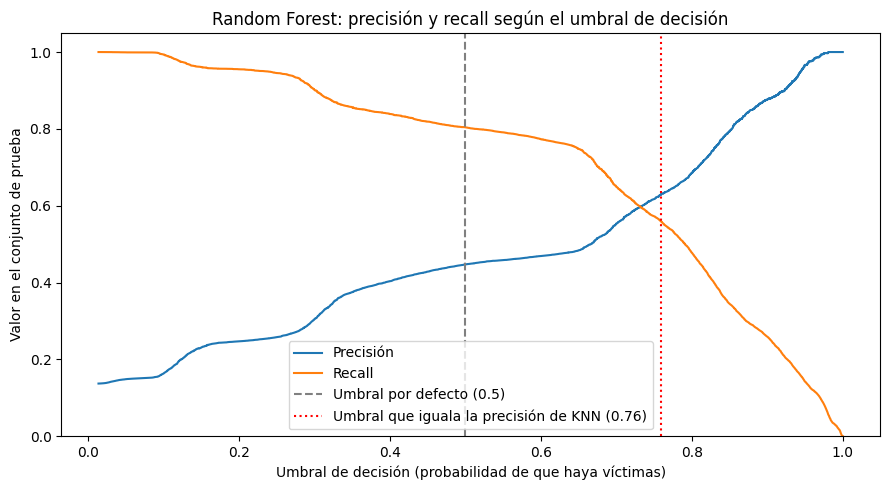


KNN, umbral 0.5: precisión 0.630 | recall 0.431
Random Forest, umbral 0.76: precisión 0.630 | recall 0.558


In [17]:
from sklearn.metrics import precision_recall_curve

# Verificación: mejor modelo en cada métrica (los AUC vienen de la sección 4.1)
comparacion = (
    results.merge(pd.DataFrame(filas_auc)[["Modelo", "AUC"]], on="Modelo")
    .set_index("Modelo")[["Accuracy", "Precision clase 1", "Recall clase 1", "F1 clase 1", "AUC"]]
)
display(comparacion.style.format("{:.4f}").highlight_max(axis=0, color="#cde8d4"))

mejor_por_metrica = comparacion.idxmax()
print("Mejor modelo en cada métrica:")
print(mejor_por_metrica.to_string())
for metrica in ["Recall clase 1", "F1 clase 1", "AUC"]:
    if mejor_por_metrica[metrica] != selected_model:
        print(f"AVISO: {selected_model} no es el mejor en {metrica}; revisar la justificación.")

# Ajuste del umbral: precisión y recall de Random Forest para cada umbral posible
proba_rf = models[selected_model].predict_proba(X_test)[:, 1]
precisiones, recalls, umbrales = precision_recall_curve(y_test, proba_rf)

# Umbral más bajo con el que Random Forest iguala la precisión de KNN
metricas_knn = results.set_index("Modelo").loc["KNN (con escalado)"]
alcanza = np.where(precisiones[:-1] >= metricas_knn["Precision clase 1"])[0]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(umbrales, precisiones[:-1], label="Precisión")
ax.plot(umbrales, recalls[:-1], label="Recall")
ax.axvline(0.5, color="gray", linestyle="--", label="Umbral por defecto (0.5)")
if len(alcanza):
    i = alcanza[0]
    ax.axvline(umbrales[i], color="red", linestyle=":",
               label=f"Umbral que iguala la precisión de KNN ({umbrales[i]:.2f})")
ax.set_title("Random Forest: precisión y recall según el umbral de decisión")
ax.set_xlabel("Umbral de decisión (probabilidad de que haya víctimas)")
ax.set_ylabel("Valor en el conjunto de prueba")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.savefig(RUTA_GRAFICAS / "fc_05_umbral_random_forest.png")
plt.show()

print(f"\nKNN, umbral 0.5: precisión {metricas_knn['Precision clase 1']:.3f} | recall {metricas_knn['Recall clase 1']:.3f}")
if len(alcanza):
    print(f"Random Forest, umbral {umbrales[i]:.2f}: precisión {precisiones[i]:.3f} | recall {recalls[i]:.3f}")
else:
    print("Random Forest no alcanza la precisión de KNN con ningún umbral.")

**Conclusiones generales:**

- Ningún modelo gana en todas las métricas: hay un intercambio entre precisión y recall. Random Forest ofrece el mejor balance y, al mover el umbral, cubre también el caso en que se priorizan menos falsas alarmas.
- El Pipeline de KNN muestra por qué los modelos basados en distancias necesitan escalado, y por qué el escalador se ajusta solo con entrenamiento para evitar data leakage.
- K-Means da una estructura débil (ver Silhouette y Davies-Bouldin en la sección 3), así que los clusters son segmentos descriptivos para enfocar campañas, no niveles de riesgo. Aun así, la tabla de la sección 4.3 muestra un segmento claro: siniestros de un solo vehículo con alta presencia de motocicletas, con una tasa de víctimas muy por encima del promedio.
- **Mejoras futuras:** hacer la imputación y la codificación dentro del Pipeline después del split, buscar hiperparámetros con validación cruzada y validar el modelo en el tiempo (entrenar con años anteriores y evaluar en los más recientes).